<a href="https://colab.research.google.com/github/ShreyaBawankar77/Hack-O-Week/blob/main/Week15_16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

wine = load_wine()

X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target

print("Dataset shape:", X.shape)
print("Wine classes:", wine.target_names)
print("First five rows:")
display(X.head())

Dataset shape: (178, 13)
Wine classes: ['class_0' 'class_1' 'class_2']
First five rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

Model accuracy: 100.0 %


In [ ]:
import pickle

with open("wine_model.pkl", "wb") as file:
    pickle.dump(model, file)

with open("wine_model.pkl", "rb") as file:
    loaded_pickle_model = pickle.load(file)

pickle_predictions = loaded_pickle_model.predict(X_test)

print("Pickle model accuracy:",
      round(accuracy_score(y_test, pickle_predictions) * 100, 2), "%")

print("First five predictions:", pickle_predictions[:5])
print("Actual classes:", y_test[:5])

Pickle model accuracy: 100.0 %
First five predictions: [0 2 0 1 1]
Actual classes: [0 2 0 1 1]


In [ ]:
import joblib

joblib.dump(model, "wine_model.joblib")

loaded_joblib_model = joblib.load("wine_model.joblib")

joblib_predictions = loaded_joblib_model.predict(X_test)

print("Joblib model accuracy:",
      round(accuracy_score(y_test, joblib_predictions) * 100, 2), "%")

print("First five predictions:", joblib_predictions[:5])

Joblib model accuracy: 100.0 %
First five predictions: [0 2 0 1 1]


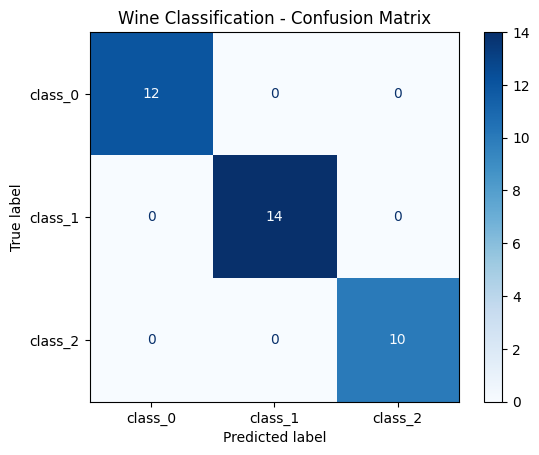

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    joblib_predictions,
    display_labels=wine.target_names,
    cmap="Blues"
)

plt.title("Wine Classification - Confusion Matrix")
plt.show()

In [ ]:
import numpy as np

# Two inputs, two weights and one bias
x = np.array([0.7, 0.3])
weights = np.array([0.5, -0.2])
bias = 0.1

z = np.dot(x, weights) + bias

# Step activation function
output = 1 if z >= 0 else 0

print("Weighted sum:", z)
print("Perceptron output:", output)

Weighted sum: 0.39
Perceptron output: 1


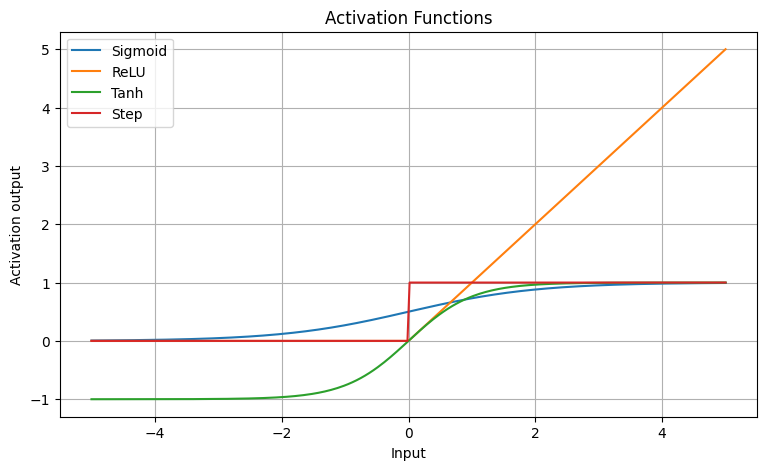

In [ ]:
x = np.linspace(-5, 5, 300)

sigmoid = 1 / (1 + np.exp(-x))
relu = np.maximum(0, x)
tanh = np.tanh(x)
step = (x >= 0).astype(int)

plt.figure(figsize=(9, 5))
plt.plot(x, sigmoid, label="Sigmoid")
plt.plot(x, relu, label="ReLU")
plt.plot(x, tanh, label="Tanh")
plt.plot(x, step, label="Step")
plt.xlabel("Input")
plt.ylabel("Activation output")
plt.title("Activation Functions")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import numpy as np

x = np.array([0.6, 0.8])
target = 1.0

weights = np.array([0.2, -0.1])
bias = 0.0
learning_rate = 0.1

# Forward propagation
z = np.dot(x, weights) + bias
prediction = 1 / (1 + np.exp(-z))

loss = (prediction - target) ** 2

# Backpropagation
sigmoid_derivative = prediction * (1 - prediction)
d_loss_d_prediction = 2 * (prediction - target)
d_loss_d_z = d_loss_d_prediction * sigmoid_derivative

d_weights = d_loss_d_z * x
d_bias = d_loss_d_z

# Update weights and bias
weights -= learning_rate * d_weights
bias -= learning_rate * d_bias

print("Prediction before update:", round(prediction, 4))
print("Loss before update:", round(loss, 4))
print("Updated weights:", weights)
print("Updated bias:", round(bias, 4))

Prediction before update: 0.51
Loss before update: 0.2401
Updated weights: [ 0.21469416 -0.08040778]
Updated bias: 0.0245


In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# Each pipeline scales data before training
sgd_model = make_pipeline(
    StandardScaler(),
    MLPClassifier(
        hidden_layer_sizes=(32,),
        solver="sgd",
        learning_rate_init=0.01,
        max_iter=500,
        random_state=42
    )
)

adam_model = make_pipeline(
    StandardScaler(),
    MLPClassifier(
        hidden_layer_sizes=(32,),
        solver="adam",
        learning_rate_init=0.01,
        max_iter=500,
        random_state=42
    )
)

sgd_model.fit(X_train, y_train)
adam_model.fit(X_train, y_train)

sgd_accuracy = accuracy_score(y_test, sgd_model.predict(X_test))
adam_accuracy = accuracy_score(y_test, adam_model.predict(X_test))

print("SGD accuracy:", round(sgd_accuracy * 100, 2), "%")
print("Adam accuracy:", round(adam_accuracy * 100, 2), "%")

SGD accuracy: 100.0 %
Adam accuracy: 97.22 %


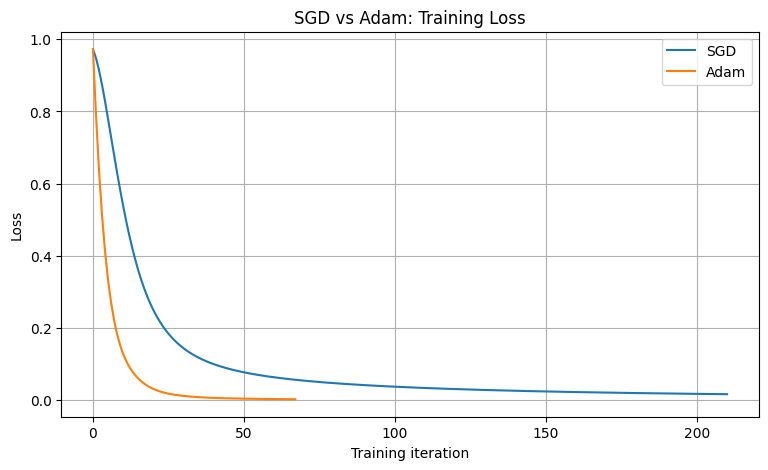

In [ ]:
sgd_loss = sgd_model.named_steps["mlpclassifier"].loss_curve_
adam_loss = adam_model.named_steps["mlpclassifier"].loss_curve_

plt.figure(figsize=(9, 5))
plt.plot(sgd_loss, label="SGD")
plt.plot(adam_loss, label="Adam")
plt.xlabel("Training iteration")
plt.ylabel("Loss")
plt.title("SGD vs Adam: Training Loss")
plt.legend()
plt.grid(True)
plt.show()

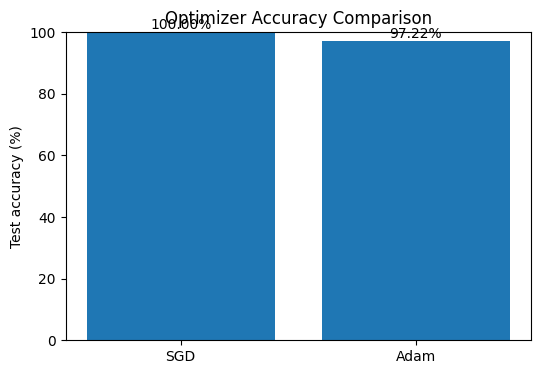

In [ ]:
optimizers = ["SGD", "Adam"]
accuracies = [sgd_accuracy * 100, adam_accuracy * 100]

plt.figure(figsize=(6, 4))
plt.bar(optimizers, accuracies)
plt.ylabel("Test accuracy (%)")
plt.title("Optimizer Accuracy Comparison")
plt.ylim(0, 100)

for i, value in enumerate(accuracies):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

wine = load_wine()
X = wine.data
y = wine.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convert class labels into one-hot vectors
num_classes = len(np.unique(y))
y_train_onehot = np.eye(num_classes)[y_train]

print("Training samples:", X_train.shape[0])
print("Input features:", X_train.shape[1])
print("Output classes:", num_classes)

Training samples: 142
Input features: 13
Output classes: 3


In [ ]:
np.random.seed(42)

input_size = X_train.shape[1]
hidden_size = 16
output_size = num_classes

W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2 / input_size)
b1 = np.zeros((1, hidden_size))

W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2 / hidden_size)
b2 = np.zeros((1, output_size))

def relu(z):
    return np.maximum(0, z)

def softmax(z):
    z = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

def cross_entropy(y_true, probabilities):
    epsilon = 1e-12
    probabilities = np.clip(probabilities, epsilon, 1 - epsilon)
    return -np.mean(
        np.sum(y_true * np.log(probabilities), axis=1)
    )

In [ ]:
epochs = 300
batch_size = 16
learning_rate = 0.01

# Adam parameters
beta1 = 0.9
beta2 = 0.999
epsilon = 1e-8

# Initialize Adam's first and second moments
parameters = {"W1": W1, "b1": b1, "W2": W2, "b2": b2}
m = {k: np.zeros_like(v) for k, v in parameters.items()}
v = {k: np.zeros_like(val) for k, val in parameters.items()}

loss_history = []
accuracy_history = []
step = 0

for epoch in range(epochs):
    # Shuffle training data each epoch
    indices = np.random.permutation(len(X_train))
    X_shuffled = X_train[indices]
    y_shuffled = y_train_onehot[indices]

    for start in range(0, len(X_train), batch_size):
        xb = X_shuffled[start:start + batch_size]
        yb = y_shuffled[start:start + batch_size]

        # Forward propagation
        z1 = xb @ W1 + b1
        a1 = relu(z1)

        z2 = a1 @ W2 + b2
        probabilities = softmax(z2)

        # Backpropagation: softmax + cross-entropy
        batch_n = len(xb)
        dz2 = (probabilities - yb) / batch_n

        dW2 = a1.T @ dz2
        db2 = np.sum(dz2, axis=0, keepdims=True)

        da1 = dz2 @ W2.T
        dz1 = da1 * (z1 > 0)

        dW1 = xb.T @ dz1
        db1 = np.sum(dz1, axis=0, keepdims=True)

        grads = {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}
        step += 1

        # Adam updates
        for key in parameters:
            m[key] = beta1 * m[key] + (1 - beta1) * grads[key]
            v[key] = beta2 * v[key] + (1 - beta2) * (grads[key] ** 2)

            m_hat = m[key] / (1 - beta1 ** step)
            v_hat = v[key] / (1 - beta2 ** step)

            parameters[key] -= (
                learning_rate * m_hat / (np.sqrt(v_hat) + epsilon)
            )

    # Record loss and accuracy on the full training set
    z1 = X_train @ W1 + b1
    a1 = relu(z1)
    probabilities = softmax(a1 @ W2 + b2)

    loss_history.append(cross_entropy(y_train_onehot, probabilities))
    accuracy_history.append(
        np.mean(np.argmax(probabilities, axis=1) == y_train)
    )

    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch {epoch + 1}: "
            f"Loss = {loss_history[-1]:.4f}, "
            f"Accuracy = {accuracy_history[-1] * 100:.2f}%"
        )

Epoch 50: Loss = 0.0008, Accuracy = 100.00%
Epoch 100: Loss = 0.0002, Accuracy = 100.00%
Epoch 150: Loss = 0.0001, Accuracy = 100.00%
Epoch 200: Loss = 0.0001, Accuracy = 100.00%
Epoch 250: Loss = 0.0000, Accuracy = 100.00%
Epoch 300: Loss = 0.0000, Accuracy = 100.00%


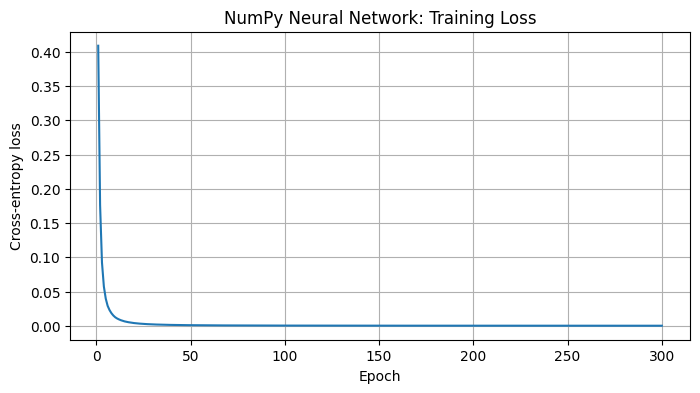

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs + 1), loss_history)
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("NumPy Neural Network: Training Loss")
plt.grid(True)
plt.show()

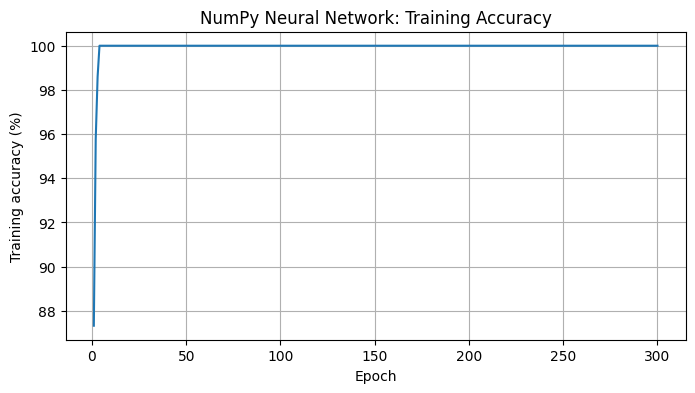

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs + 1), np.array(accuracy_history) * 100)
plt.xlabel("Epoch")
plt.ylabel("Training accuracy (%)")
plt.title("NumPy Neural Network: Training Accuracy")
plt.grid(True)
plt.show()

In [ ]:
# Forward propagation on test data
z1_test = X_test @ W1 + b1
a1_test = relu(z1_test)
test_probabilities = softmax(a1_test @ W2 + b2)

y_test_pred = np.argmax(test_probabilities, axis=1)

test_accuracy = accuracy_score(y_test, y_test_pred)

print("Test accuracy:", round(test_accuracy * 100, 2), "%")
print("Actual classes:   ", y_test[:10])
print("Predicted classes:", y_test_pred[:10])

Test accuracy: 94.44 %
Actual classes:    [0 2 0 1 1 0 0 1 1 2]
Predicted classes: [0 1 0 1 1 0 0 1 1 2]


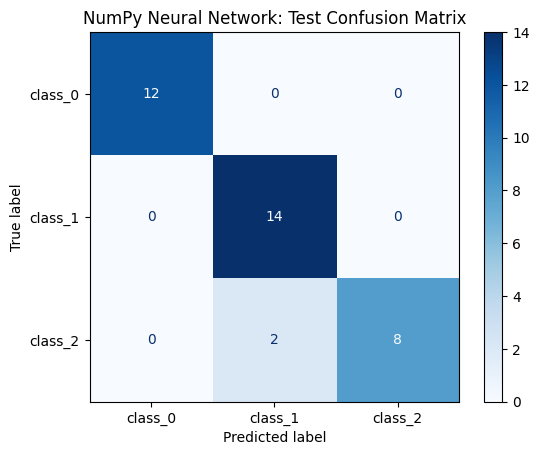

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=wine.target_names,
    cmap="Blues"
)

plt.title("NumPy Neural Network: Test Confusion Matrix")
plt.show()